# Cerro Alegre - YOLO11n-seg y YOLO11s-seg

## 1. Preparación compartida

### 1.1 Instalación de dependencias

In [1]:
!pip -q install ultralytics geopandas rasterio shapely pyogrio

### 1.2 Configuración general y rutas

In [4]:
from pathlib import Path
import warnings, shutil, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import Window
from rasterio.features import geometry_mask
import geopandas as gpd
from shapely.geometry import box, Polygon, MultiPolygon, mapping
from shapely import make_valid
import itertools

from google.colab import drive
drive.mount('/content/drive')

warnings.filterwarnings('ignore')

BASE_DIR = Path('/content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega')
DATA_DIR = BASE_DIR / 'datos'

DATASET_DIR = BASE_DIR / 'dataset_yolo_split_bloques'
RUNS_DIR = BASE_DIR / 'runs'
DIAG_DIR = BASE_DIR / 'diagnosticos_split_bloques'

for d in [DATA_DIR, DATASET_DIR, RUNS_DIR, DIAG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

RASTER_PATH = DATA_DIR / 'Cerro_Alegre_Censo_Clip_uint8_global.tif'
VECTOR_PATH = DATA_DIR / 'copas_totales_corregidas_cerro_alegre.gpkg'
ZONE_PATH = DIAG_DIR / 'zonas_validas_inferidas.gpkg'

# Teselado original
TILE_SIZE = 640
OVERLAP = 0.20
STRIDE = int(TILE_SIZE * (1 - OVERLAP))
MIN_VALID_FRACTION = 0.10

# Expansión alrededor de cada copa para unir copas cercanas
ZONE_BUFFER_M = 2.5

# Descarta componentes muy pequeños/aislados de la zona inferida
MIN_ZONE_AREA_M2 = 300

# Proporción mínima del tile que debe estar dentro de la zona válida.
# Como además enmascaramos el exterior, usamos 0.15 según el diagnóstico realizado.
MIN_TILE_ZONE_FRACTION = 0.15

# Si True, todo píxel del tile fuera de la zona válida queda en 0 (NoData)
MASK_OUTSIDE_ZONE = True

TRAIN_FRAC = 0.70
VAL_FRAC = 0.15
TEST_FRAC = 0.15
SEED = 42

print('BASE_DIR:', BASE_DIR)
print('RASTER_PATH:', RASTER_PATH)
print('VECTOR_PATH:', VECTOR_PATH)
print('DATASET_DIR:', DATASET_DIR)
print('TILE_SIZE:', TILE_SIZE)
print('STRIDE:', STRIDE)
print('ZONE_BUFFER_M:', ZONE_BUFFER_M)
print('MIN_TILE_ZONE_FRACTION:', MIN_TILE_ZONE_FRACTION)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BASE_DIR: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega
RASTER_PATH: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/datos/Cerro_Alegre_Censo_Clip_uint8_global.tif
VECTOR_PATH: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/datos/copas_totales_corregidas_cerro_alegre.gpkg
DATASET_DIR: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/dataset_yolo_split_bloques
TILE_SIZE: 640
STRIDE: 512
ZONE_BUFFER_M: 2.5
MIN_TILE_ZONE_FRACTION: 0.15


### 1.3 Leer y reparar copas etiquetadas

In [5]:
with rasterio.open(RASTER_PATH) as src:
    print('Raster:', src.width, 'x', src.height)
    print('Bandas:', src.count)
    print('dtype:', src.dtypes)
    print('CRS:', src.crs)
    print('NoData:', src.nodata)
    print('Resolución:', src.res)
    raster_crs = src.crs

gdf = gpd.read_file(VECTOR_PATH)

print('\nCopas originales:', len(gdf))
print('CRS copas:', gdf.crs)
print('Tipos:', gdf.geom_type.value_counts().to_dict())

if gdf.crs != raster_crs:
    gdf = gdf.to_crs(raster_crs)

# Reparar geometrías
print('Geometrías inválidas antes:', (~gdf.geometry.is_valid).sum())
gdf['geometry'] = gdf.geometry.apply(
    lambda geom: make_valid(geom) if geom is not None and not geom.is_valid else geom
)
gdf = gdf[gdf.geometry.notna() & (~gdf.geometry.is_empty)].copy()
gdf = gdf[gdf.geom_type.isin(['Polygon', 'MultiPolygon'])].copy()

print('Geometrías inválidas después:', (~gdf.geometry.is_valid).sum())
print('Copas utilizables:', len(gdf))

Raster: 2098 x 6373
Bandas: 3
dtype: ('uint8', 'uint8', 'uint8')
CRS: EPSG:32721
NoData: 0.0
Resolución: (0.19440213111415683, 0.1944156425394072)

Copas originales: 997
CRS copas: EPSG:32721
Tipos: {'MultiPolygon': 997}
Geometrías inválidas antes: 0
Geometrías inválidas después: 0
Copas utilizables: 997


### 1.4 Delimitar zonas completamente etiquetadas

In [6]:
# Buffer de cada copa y disolución
buffered = gdf.geometry.buffer(ZONE_BUFFER_M)
merged = buffered.unary_union

# Separar componentes
if isinstance(merged, Polygon):
    zone_parts = [merged]
elif isinstance(merged, MultiPolygon):
    zone_parts = list(merged.geoms)
else:
    zone_parts = [geom for geom in getattr(merged, 'geoms', []) if isinstance(geom, Polygon)]

zone_parts_df = gpd.GeoDataFrame(
    {'zone_id': range(1, len(zone_parts) + 1)},
    geometry=zone_parts,
    crs=raster_crs
)
zone_parts_df['area_m2'] = zone_parts_df.geometry.area

print('Componentes antes del filtro:', len(zone_parts_df))
print(zone_parts_df['area_m2'].describe())

zone_parts_keep = zone_parts_df[
    zone_parts_df['area_m2'] >= MIN_ZONE_AREA_M2
].copy()

assert len(zone_parts_keep) > 0, (
    'No quedó ninguna zona válida. Bajá MIN_ZONE_AREA_M2 o aumentá ZONE_BUFFER_M.'
)

valid_zone_geom = zone_parts_keep.geometry.unary_union

valid_zones_gdf = gpd.GeoDataFrame(
    {'zone_id': range(1, len(zone_parts_keep) + 1),
     'area_m2': zone_parts_keep.geometry.area.values},
    geometry=zone_parts_keep.geometry.values,
    crs=raster_crs
)

# Guardar para poder verla también en QGIS si quieren
if ZONE_PATH.exists():
    ZONE_PATH.unlink()
valid_zones_gdf.to_file(ZONE_PATH, driver='GPKG')

print('\nZonas válidas inferidas:', len(valid_zones_gdf))
print('Área total válida (ha):', valid_zones_gdf.geometry.area.sum() / 10000)
print('Guardadas en:', ZONE_PATH)

Componentes antes del filtro: 4
count        4.000000
mean     19301.082443
std      12931.245360
min       4472.520383
25%      13935.561033
50%      18398.036958
75%      23763.558368
max      35935.735473
Name: area_m2, dtype: float64

Zonas válidas inferidas: 4
Área total válida (ha): 7.720432977148357
Guardadas en: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/diagnosticos_split_bloques/zonas_validas_inferidas.gpkg


### 1.5 Revisar las zonas

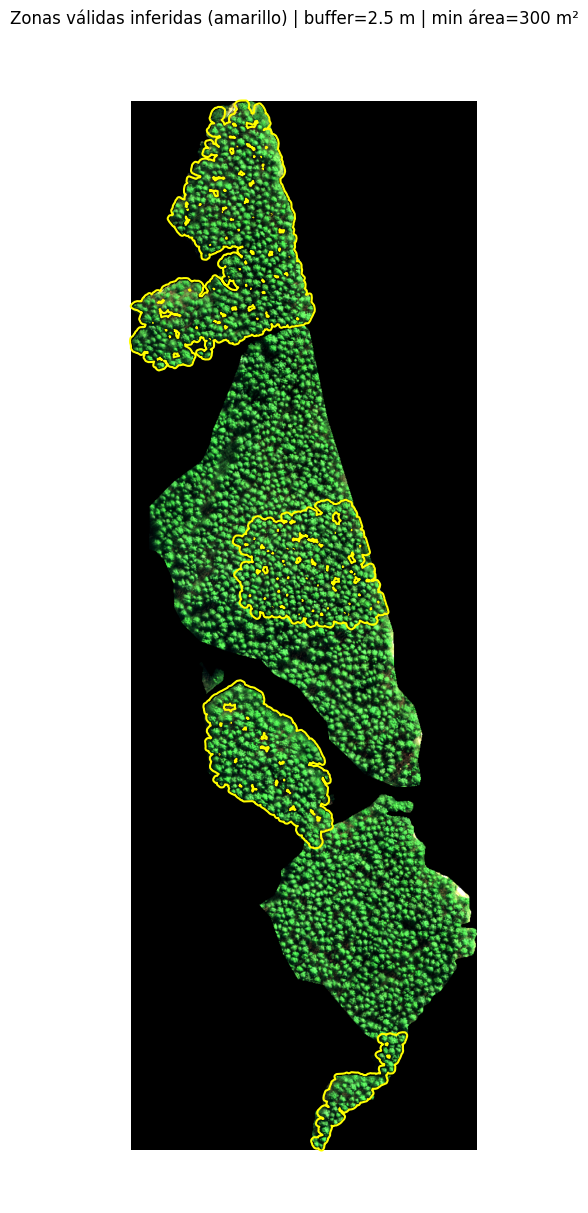

In [7]:
with rasterio.open(RASTER_PATH) as src:
    scale = min(1.0, 1800 / max(src.width, src.height))
    out_h = max(1, int(src.height * scale))
    out_w = max(1, int(src.width * scale))
    img = src.read(out_shape=(src.count, out_h, out_w))
    extent = [src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]

img_show = np.moveaxis(img, 0, -1)
if img_show.shape[-1] > 3:
    img_show = img_show[..., :3]

plt.figure(figsize=(9, 15))
plt.imshow(img_show, extent=extent)

# Zonas válidas inferidas
valid_zones_gdf.boundary.plot(ax=plt.gca(), linewidth=1.5, color='yellow')

plt.title(
    f'Zonas válidas inferidas (amarillo) | buffer={ZONE_BUFFER_M} m | '
    f'min área={MIN_ZONE_AREA_M2} m²'
)
plt.axis('off')
plt.show()

### 1.6 Crear carpetas del dataset

In [8]:
# Preparar imágenes y etiquetas por partición.
IMAGES_DIR = DATASET_DIR / 'images'
LABELS_DIR = DATASET_DIR / 'labels'
META_DIR = DATASET_DIR / 'metadata'

# Limpiar solamente el NUEVO dataset para evitar mezclar ejecuciones anteriores
if DATASET_DIR.exists():
    for sub in ['images', 'labels', 'metadata']:
        p = DATASET_DIR / sub
        if p.exists():
            shutil.rmtree(p)

for split in ['train', 'val', 'test']:
    (IMAGES_DIR / split).mkdir(parents=True, exist_ok=True)
    (LABELS_DIR / split).mkdir(parents=True, exist_ok=True)
META_DIR.mkdir(parents=True, exist_ok=True)

print('Estructura limpia creada:', DATASET_DIR)

Estructura limpia creada: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/dataset_yolo_split_bloques


### 1.6 Funciones auxiliares

In [9]:
#Conversión de polígonos a coordenadas YOLO y máscara de datos válidos.
def get_valid_mask(data, nodata=None):
    if nodata is not None:
        return np.any(data != nodata, axis=0)
    return np.any(data != 0, axis=0)


def polygon_to_yolo_coords(geom, tile_transform, tile_width, tile_height):
    inv = ~tile_transform
    out = []

    if geom is None or geom.is_empty:
        return out

    if isinstance(geom, Polygon):
        geoms = [geom]
    elif isinstance(geom, MultiPolygon):
        geoms = list(geom.geoms)
    else:
        geoms = []

    for poly in geoms:
        if poly.is_empty or poly.area <= 0:
            continue

        coords = list(poly.exterior.coords)
        if len(coords) > 1 and coords[0] == coords[-1]:
            coords = coords[:-1]
        if len(coords) < 3:
            continue

        normalized = []
        ok = True

        for x_map, y_map in coords:
            col, row = inv * (x_map, y_map)
            xn = min(max(col / tile_width, 0.0), 1.0)
            yn = min(max(row / tile_height, 0.0), 1.0)

            if not (np.isfinite(xn) and np.isfinite(yn)):
                ok = False
                break
            normalized.extend([xn, yn])

        if ok and len(normalized) >= 6:
            out.append(normalized)

    return out

### 1.7 Seleccionar teselas

In [11]:
#Medir cobertura válida y proporción dentro de las zonas etiquetadas.
tiles = []

with rasterio.open(RASTER_PATH) as src:
    tile_id = 0

    for y in range(0, src.height, STRIDE):
        for x in range(0, src.width, STRIDE):

            tile_w = min(TILE_SIZE, src.width - x)
            tile_h = min(TILE_SIZE, src.height - y)

            if tile_w < TILE_SIZE / 4 or tile_h < TILE_SIZE / 4:
                continue

            window = Window(x, y, tile_w, tile_h)
            data = src.read(window=window)
            valid_fraction = float(get_valid_mask(data, src.nodata).mean())

            if valid_fraction < MIN_VALID_FRACTION:
                continue

            bounds = rasterio.windows.bounds(window, src.transform)
            tile_geom = box(bounds[0], bounds[1], bounds[2], bounds[3])

            inter = tile_geom.intersection(valid_zone_geom)
            zone_fraction = 0.0 if inter.is_empty else float(inter.area / tile_geom.area)

            tiles.append({
                'tile_id': tile_id,
                'x': x,
                'y': y,
                'width': tile_w,
                'height': tile_h,
                'valid_fraction': valid_fraction,
                'zone_fraction': zone_fraction,
                'left': bounds[0],
                'bottom': bounds[1],
                'right': bounds[2],
                'top': bounds[3],
                'center_x': (bounds[0] + bounds[2]) / 2,
                'center_y': (bounds[1] + bounds[3]) / 2
            })

            tile_id += 1

tiles_all_df = pd.DataFrame(tiles)

print('Teselas candidatas en todo el raster:', len(tiles_all_df))

# Diagnóstico de cuántas sobrevivirían con distintos umbrales
thresholds = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 1.00]
threshold_table = pd.DataFrame({
    'min_zone_fraction': thresholds,
    'n_tiles': [(tiles_all_df['zone_fraction'] >= t).sum() for t in thresholds]
})
display(threshold_table)

# Aplicar umbral elegido
# Exigimos además que haya alguna zona válida en el tile
tiles_df = tiles_all_df[
    tiles_all_df['zone_fraction'] >= MIN_TILE_ZONE_FRACTION
].copy()

assert len(tiles_df) > 0, (
    'No quedaron tiles. Bajá MIN_TILE_ZONE_FRACTION o revisá las zonas inferidas.'
)

print(f'Tiles seleccionados con zone_fraction >= {MIN_TILE_ZONE_FRACTION}:', len(tiles_df))
display(tiles_df[['tile_id', 'zone_fraction', 'valid_fraction']].head(20))

Teselas candidatas en todo el raster: 34


,min_zone_fraction,n_tiles
0,0.50,7
1,0.60,5
2,0.70,2
3,0.80,1
4,0.90,0
5,0.95,0
6,1.00,0


Tiles seleccionados con zone_fraction >= 0.15: 17


,tile_id,zone_fraction,valid_fraction
0,0,0.314525,0.352197
1,1,0.551214,0.568750
2,2,0.423734,0.420220
3,3,0.728034,0.718210
4,4,0.643346,0.643877
5,5,0.523780,0.787913
10,10,0.192045,1.000000
11,11,0.205704,0.472888
13,13,0.678449,1.000000
14,14,0.675701,0.718459


### 1.8 Inspeccionar teselas candidatas

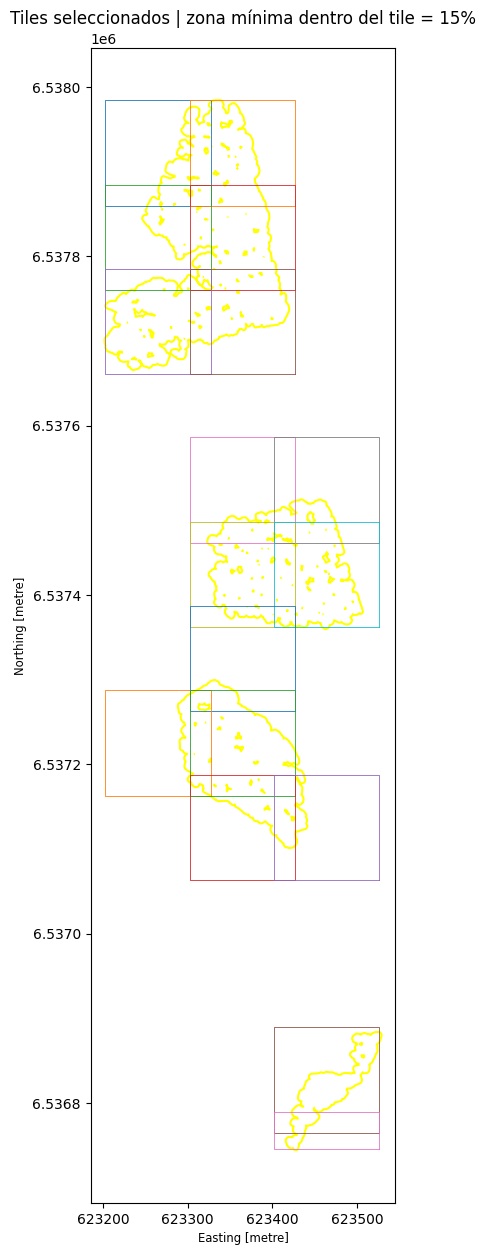

In [12]:
#Visualizar la selección espacial.
fig, ax = plt.subplots(figsize=(9, 15))
valid_zones_gdf.boundary.plot(ax=ax, linewidth=1.5, color='yellow')

for _, r in tiles_df.iterrows():
    geom = box(r['left'], r['bottom'], r['right'], r['top'])
    xs, ys = geom.exterior.xy
    ax.plot(xs, ys, linewidth=0.6)

ax.set_aspect('equal', adjustable='box')
ax.set_title(
    f'Tiles seleccionados | zona mínima dentro del tile = {MIN_TILE_ZONE_FRACTION:.0%}'
)
plt.show()

### 1.9 Separar train, val y test

Copas sin bloque asignado: 0

Bloques detectados y cantidad de copas:


,zone_id,copas_unicas,area_m2
0,1,459,35935.735473
1,2,201,17089.907916
2,3,281,19706.166000
3,4,56,4472.520383



Asignación automática de bloques:


,zone_id,split,copas_unicas,fraccion_copas,area_m2
3,4,test,56,0.056169,4472.520383
0,1,train,459,0.460381,35935.735473
2,3,train,281,0.281846,19706.166000
1,2,val,201,0.201605,17089.907916



Copas únicas por split ANTES del teselado:


,split,bloques,copas_unicas,fraccion
0,test,1,56,0.056169
1,train,2,740,0.742227
2,val,1,201,0.201605


Bloques guardados en: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/diagnosticos_split_bloques/bloques_split.gpkg
Copas con split guardadas en: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/diagnosticos_split_bloques/copas_split_bloques.gpkg

Tiles definitivos por split:
split
train    10
val       4
test      2
Name: count, dtype: int64

Tiles descartados:


,cantidad
reason,
mezcla_bloques_de_distintos_splits,1



Cada copa pertenece a un solo split.
Cada bloque completo pertenece a un solo split.


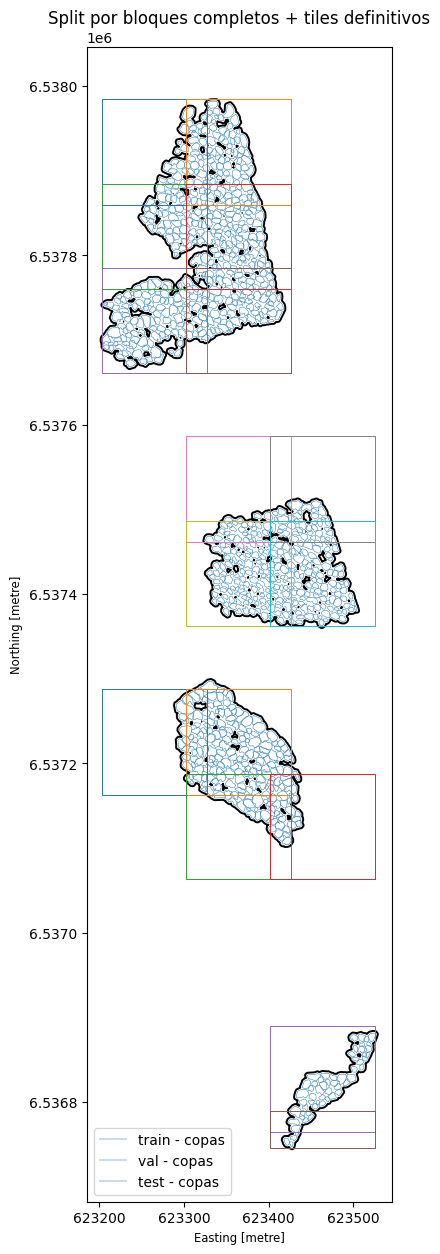

In [13]:
#  Asignar cada copa a uno de los bloques espaciales
gdf = gdf.reset_index(drop=True).copy()
gdf["crown_id"] = np.arange(len(gdf), dtype=int)

# Asegurar zone_id estable
valid_zones_gdf = valid_zones_gdf.reset_index(drop=True).copy()
valid_zones_gdf["zone_id"] = np.arange(1, len(valid_zones_gdf) + 1, dtype=int)

zone_sindex = valid_zones_gdf.sindex

def assign_crown_to_zone(geom):
    # Asigna una copa al bloque válido con mayor intersección.
    candidate_idx = list(zone_sindex.intersection(geom.bounds))
    if len(candidate_idx) == 0:
        return None

    candidates = valid_zones_gdf.iloc[candidate_idx]

    best_zone = None
    best_area = -1.0

    for _, z in candidates.iterrows():
        inter_area = geom.intersection(z.geometry).area
        if inter_area > best_area:
            best_area = inter_area
            best_zone = int(z["zone_id"])

    return best_zone

gdf["zone_id"] = gdf.geometry.apply(assign_crown_to_zone)

n_without_zone = int(gdf["zone_id"].isna().sum())
print("Copas sin bloque asignado:", n_without_zone)

assert n_without_zone == 0, (
    "Hay copas que no quedaron asociadas a ninguna zona válida. "
    "Revisá ZONE_BUFFER_M o MIN_ZONE_AREA_M2."
)

gdf["zone_id"] = gdf["zone_id"].astype(int)

block_counts = (
    gdf.groupby("zone_id")
       .agg(copas_unicas=("crown_id", "nunique"))
       .reset_index()
)

block_counts = block_counts.merge(
    valid_zones_gdf[["zone_id", "area_m2"]],
    on="zone_id",
    how="left"
)

print("\nBloques detectados y cantidad de copas:")
display(block_counts.sort_values("zone_id"))


#  Buscar automáticamente una asignación de bloques
zone_ids = block_counts["zone_id"].astype(int).tolist()

count_map = dict(
    zip(
        block_counts["zone_id"].astype(int),
        block_counts["copas_unicas"].astype(int)
    )
)

total_crowns = int(block_counts["copas_unicas"].sum())

targets = {
    "train": total_crowns * TRAIN_FRAC,
    "val": total_crowns * VAL_FRAC,
    "test": total_crowns * TEST_FRAC
}

splits = ["train", "val", "test"]

assert len(zone_ids) >= 3, (
    f"Solo hay {len(zone_ids)} bloques válidos. "
    "Se necesitan al menos 3 para train/val/test por bloques."
)

best_assignment = None
best_score = float("inf")

if len(zone_ids) <= 12:

    for assignment in itertools.product(splits, repeat=len(zone_ids)):

        # Los tres splits deben recibir al menos un bloque
        if set(assignment) != set(splits):
            continue

        counts = {s: 0 for s in splits}

        for zone_id, split in zip(zone_ids, assignment):
            counts[split] += count_map[zone_id]

        score = sum(
            ((counts[s] - targets[s]) / max(targets[s], 1)) ** 2
            for s in splits
        )

        if score < best_score:
            best_score = score
            best_assignment = dict(zip(zone_ids, assignment))

else:
    # Fallback si hubiese muchos bloques
    ordered = sorted(zone_ids, key=lambda z: count_map[z], reverse=True)
    best_assignment = {}
    counts = {s: 0 for s in splits}

    for split, zone_id in zip(splits, ordered[:3]):
        best_assignment[zone_id] = split
        counts[split] += count_map[zone_id]

    for zone_id in ordered[3:]:
        deficits = {
            s: targets[s] - counts[s]
            for s in splits
        }
        split = max(deficits, key=deficits.get)
        best_assignment[zone_id] = split
        counts[split] += count_map[zone_id]

assert best_assignment is not None

valid_zones_gdf["split"] = valid_zones_gdf["zone_id"].map(best_assignment)
gdf["split_crown"] = gdf["zone_id"].map(best_assignment)

assert valid_zones_gdf["split"].notna().all()
assert gdf["split_crown"].notna().all()

block_split_df = block_counts.copy()
block_split_df["split"] = block_split_df["zone_id"].map(best_assignment)

block_split_df["fraccion_copas"] = (
    block_split_df["copas_unicas"] / total_crowns
)

print("\nAsignación automática de bloques:")
display(
    block_split_df[
        ["zone_id", "split", "copas_unicas", "fraccion_copas", "area_m2"]
    ].sort_values(["split", "zone_id"])
)

crowns_by_split = (
    gdf.groupby("split_crown")
       .agg(
           bloques=("zone_id", "nunique"),
           copas_unicas=("crown_id", "nunique")
       )
       .reset_index()
       .rename(columns={"split_crown": "split"})
)

crowns_by_split["fraccion"] = (
    crowns_by_split["copas_unicas"] / len(gdf)
)

print("\nCopas únicas por split ANTES del teselado:")
display(crowns_by_split)

blocks_split_path = DIAG_DIR / "bloques_split.gpkg"
crowns_split_path = DIAG_DIR / "copas_split_bloques.gpkg"

if blocks_split_path.exists():
    blocks_split_path.unlink()

if crowns_split_path.exists():
    crowns_split_path.unlink()

valid_zones_gdf.to_file(blocks_split_path, driver="GPKG")
gdf.to_file(crowns_split_path, driver="GPKG")

block_split_df.to_csv(
    DIAG_DIR / "asignacion_bloques.csv",
    index=False
)

print("Bloques guardados en:", blocks_split_path)
print("Copas con split guardadas en:", crowns_split_path)


# Asignar tiles según los bloques que intersectan
zone_sindex = valid_zones_gdf.sindex

tile_rows = []
discarded_rows = []

for _, row in tiles_df.iterrows():

    tile_geom = box(
        row["left"], row["bottom"],
        row["right"], row["top"]
    )

    candidate_idx = list(
        zone_sindex.intersection(tile_geom.bounds)
    )

    zones_hit = valid_zones_gdf.iloc[candidate_idx].copy()

    if len(zones_hit) > 0:
        zones_hit["inter_area"] = zones_hit.geometry.apply(
            lambda geom: geom.intersection(tile_geom).area
        )
        zones_hit = zones_hit[zones_hit["inter_area"] > 0].copy()

    if len(zones_hit) == 0:
        discarded_rows.append({
            **row.to_dict(),
            "reason": "sin_bloque_valido"
        })
        continue

    splits_present = sorted(
        zones_hit["split"].dropna().unique().tolist()
    )

    if len(splits_present) != 1:
        discarded_rows.append({
            **row.to_dict(),
            "reason": "mezcla_bloques_de_distintos_splits",
            "splits_present": ",".join(splits_present),
            "zone_ids": ",".join(
                map(str, sorted(zones_hit["zone_id"].astype(int).tolist()))
            )
        })
        continue

    split = splits_present[0]

    zones_same_split = zones_hit[zones_hit["split"] == split]

    zone_ids_in_tile = sorted(
        zones_same_split["zone_id"].astype(int).tolist()
    )

    split_zone_fraction = float(
        zones_same_split["inter_area"].sum() / tile_geom.area
    )

    tile_rows.append({
        **row.to_dict(),
        "split": split,
        "zone_ids_in_tile": ",".join(map(str, zone_ids_in_tile)),
        "split_zone_fraction": split_zone_fraction
    })

tiles_split_df = pd.DataFrame(tile_rows)
discarded_tiles_df = pd.DataFrame(discarded_rows)

assert len(tiles_split_df) > 0, (
    "No quedaron tiles después de asignarlos por bloques."
)

tiles_df = tiles_split_df.copy()

print("\nTiles definitivos por split:")
print(tiles_df["split"].value_counts())

print("\nTiles descartados:")
if len(discarded_tiles_df) > 0:
    display(discarded_tiles_df["reason"].value_counts().rename("cantidad"))
else:
    print("0")

tiles_df.to_csv(
    DIAG_DIR / "tiles_split_bloques.csv",
    index=False
)

discarded_tiles_df.to_csv(
    DIAG_DIR / "tiles_descartados_bloques.csv",
    index=False
)


# Verificaciones previas
assert gdf.groupby("crown_id")["split_crown"].nunique().max() == 1
assert valid_zones_gdf.groupby("zone_id")["split"].nunique().max() == 1

print("\nCada copa pertenece a un solo split.")
print("Cada bloque completo pertenece a un solo split.")


# Visualización espacial
fig, ax = plt.subplots(figsize=(9, 15))

for split in ["train", "val", "test"]:
    sub = gdf[gdf["split_crown"] == split]
    if len(sub) > 0:
        sub.boundary.plot(
            ax=ax,
            linewidth=0.35,
            label=f"{split} - copas"
        )

valid_zones_gdf.boundary.plot(
    ax=ax,
    linewidth=1.4,
    color="black"
)

for _, r in tiles_df.iterrows():
    geom = box(
        r["left"], r["bottom"],
        r["right"], r["top"]
    )
    xs, ys = geom.exterior.xy
    ax.plot(xs, ys, linewidth=0.7)

ax.set_aspect("equal", adjustable="box")
ax.set_title(
    "Split por bloques completos + tiles definitivos"
)
ax.legend()
plt.show()


### 1.10 Exportar imágenes y etiquetas

In [14]:
# Generar las imágenes y las máscaras poligonales en formato YOLO.
# Índices espaciales
crown_sindex = gdf.sindex
zone_sindex = valid_zones_gdf.sindex

metadata_rows = []

# Limpiar dataset anterior de esta versión
for split in ["train", "val", "test"]:
    for folder in [IMAGES_DIR / split, LABELS_DIR / split]:
        if folder.exists():
            for p in folder.glob("*"):
                if p.is_file():
                    p.unlink()

with rasterio.open(RASTER_PATH) as src:

    for _, row in tiles_df.iterrows():

        split = row["split"]
        tile_name = f"tile_{int(row['tile_id']):04d}"

        image_path = IMAGES_DIR / split / f"{tile_name}.tif"
        label_path = LABELS_DIR / split / f"{tile_name}.txt"

        window = Window(
            int(row["x"]), int(row["y"]),
            int(row["width"]), int(row["height"])
        )

        tile_data = src.read(window=window)
        tile_transform = src.window_transform(window)

        tile_geom = box(
            row["left"], row["bottom"],
            row["right"], row["top"]
        )

        # Zona visible = únicamente bloques del MISMO split
        zone_candidate_idx = list(
            zone_sindex.intersection(tile_geom.bounds)
        )

        zones_here = valid_zones_gdf.iloc[
            zone_candidate_idx
        ].copy()

        zones_here = zones_here[
            (zones_here["split"] == split) &
            (zones_here.geometry.intersects(tile_geom))
        ].copy()

        assert len(zones_here) > 0, (
            f"Tile {tile_name} no tiene bloque válido para split {split}"
        )

        split_zone_geom = zones_here.geometry.unary_union
        valid_in_tile = split_zone_geom.intersection(tile_geom)

        # MÁSCARA: fuera de los bloques de este split => 0
        if MASK_OUTSIDE_ZONE:
            inside_mask = geometry_mask(
                [mapping(valid_in_tile)],
                out_shape=(
                    int(row["height"]),
                    int(row["width"])
                ),
                transform=tile_transform,
                invert=True
            )
            tile_data[:, ~inside_mask] = 0

        # Guardar GeoTIFF
        profile = src.profile.copy()
        profile.pop("blockxsize", None)
        profile.pop("blockysize", None)
        profile.pop("tiled", None)

        profile.update({
            "height": int(row["height"]),
            "width": int(row["width"]),
            "transform": tile_transform,
            "nodata": 0
        })

        with rasterio.open(
            image_path,
            "w",
            **profile
        ) as dst:
            dst.write(tile_data)

        # Etiquetas: SOLO copas del mismo split
        candidate_idx = list(
            crown_sindex.intersection(tile_geom.bounds)
        )

        candidates = gdf.iloc[candidate_idx].copy()

        candidates = candidates[
            (candidates["split_crown"] == split) &
            (candidates.geometry.intersects(tile_geom))
        ].copy()

        yolo_lines = []
        crown_ids_written = set()

        for _, crown in candidates.iterrows():

            geom = crown.geometry

            if geom is None or geom.is_empty:
                continue

            clipped = (
                geom
                .intersection(tile_geom)
                .intersection(valid_in_tile)
            )

            if clipped.is_empty:
                continue

            polygons = polygon_to_yolo_coords(
                clipped,
                tile_transform,
                int(row["width"]),
                int(row["height"])
            )

            wrote_this_crown = False

            for coords in polygons:
                yolo_lines.append(
                    "0 " + " ".join(
                        f"{v:.6f}" for v in coords
                    )
                )
                wrote_this_crown = True

            if wrote_this_crown:
                crown_ids_written.add(
                    int(crown["crown_id"])
                )

        with open(label_path, "w") as f:
            if yolo_lines:
                f.write("\n".join(yolo_lines))

        metadata_rows.append({
            **row.to_dict(),
            "image_path": str(image_path),
            "label_path": str(label_path),
            "n_crowns": len(crown_ids_written),
            "has_crowns": len(crown_ids_written) > 0,
            "crown_ids_written": ",".join(
                map(str, sorted(crown_ids_written))
            ),
            "n_yolo_polygons": len(yolo_lines)
        })

meta_df = pd.DataFrame(metadata_rows)

meta_path = META_DIR / "tiles_metadata.csv"
meta_df.to_csv(meta_path, index=False)

print("Metadatos:", meta_path)


Metadatos: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/dataset_yolo_split_bloques/metadata/tiles_metadata.csv


### 1.11 Diagnóstico del dataset

In [15]:
# Resumen de dataset por split
summary = (
    meta_df.groupby("split")
    .agg(
        tiles=("tile_id", "count"),
        tiles_con_copas=("has_crowns", "sum"),
        apariciones_copas_en_tiles=("n_crowns", "sum"),
        zone_fraction_media=("split_zone_fraction", "mean")
    )
    .reset_index()
)

summary["tiles_sin_copas"] = (
    summary["tiles"] - summary["tiles_con_copas"]
)

unique_counts = []

for split in ["train", "val", "test"]:

    ids = set()

    sub = meta_df[
        meta_df["split"] == split
    ]

    for txt in sub["crown_ids_written"]:
        ids.update(
            int(x)
            for x in str(txt).split(",")
            if str(x).strip() != ""
        )

    unique_counts.append({
        "split": split,
        "copas_unicas_en_tiles": len(ids)
    })

unique_df = pd.DataFrame(unique_counts)

summary = summary.merge(
    unique_df,
    on="split",
    how="outer"
).fillna(0)

assigned_summary = (
    gdf.groupby("split_crown")
       .agg(
           bloques=("zone_id", "nunique"),
           copas_unicas_asignadas=("crown_id", "nunique")
       )
       .reset_index()
       .rename(columns={"split_crown": "split"})
)

summary = summary.merge(
    assigned_summary,
    on="split",
    how="outer"
).fillna(0)

display(summary)

summary.to_csv(
    DIAG_DIR / "resumen_dataset_split_bloques.csv",
    index=False
)

print("\nTotal de copas originales:", len(gdf))
print(
    "Copas únicas asignadas a bloques:",
    int(
        assigned_summary["copas_unicas_asignadas"].sum()
    )
)
print(
    "Copas únicas representadas en tiles:",
    int(summary["copas_unicas_en_tiles"].sum())
)


# Verificación fuerte de leakage
split_sets = {}

for split in ["train", "val", "test"]:

    ids = set()

    sub = meta_df[
        meta_df["split"] == split
    ]

    for txt in sub["crown_ids_written"]:
        ids.update(
            int(x)
            for x in str(txt).split(",")
            if str(x).strip() != ""
        )

    split_sets[split] = ids

train_val_overlap = (
    split_sets["train"] & split_sets["val"]
)
train_test_overlap = (
    split_sets["train"] & split_sets["test"]
)
val_test_overlap = (
    split_sets["val"] & split_sets["test"]
)

print(
    "\nCopas compartidas train-val:",
    len(train_val_overlap)
)
print(
    "Copas compartidas train-test:",
    len(train_test_overlap)
)
print(
    "Copas compartidas val-test:",
    len(val_test_overlap)
)

assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

print(
    "\nVerificación aprobada: "
    "ninguna copa aparece en más de un split."
)


# Control de bloques indivisibles
block_check = (
    gdf.groupby("zone_id")["split_crown"]
       .nunique()
)

assert int(block_check.max()) == 1

print(
    "Verificación aprobada: "
    "ningún bloque fue dividido entre splits."
)


# Resumen legible
for split in ["train", "val", "test"]:

    row = summary[
        summary["split"] == split
    ]

    if len(row) == 0:
        print(split, "| SIN DATOS")
        continue

    r = row.iloc[0]

    print(
        split,
        "| bloques:", int(r["bloques"]),
        "| tiles:", int(r["tiles"]),
        "| copas únicas asignadas:",
        int(r["copas_unicas_asignadas"]),
        "| copas únicas en tiles:",
        int(r["copas_unicas_en_tiles"])
    )

missing = [
    s for s in ["train", "val", "test"]
    if s not in set(meta_df["split"])
]

if missing:
    print(
        "\n⚠️ No entrenar todavía. "
        "Faltan splits con tiles:",
        missing
    )
else:
    print(
        "\nHay tiles en train, val y test."
    )
    print(
        "Si la distribución de copas es razonable, "
        "se puede continuar al entrenamiento."
    )


,split,tiles,tiles_con_copas,apariciones_copas_en_tiles,zone_fraction_media,tiles_sin_copas,copas_unicas_en_tiles,bloques,copas_unicas_asignadas
0,test,2,2,64,0.214209,0,56,1,56
1,train,10,10,1111,0.493653,0,740,2,740
2,val,4,4,338,0.393309,0,201,1,201



Total de copas originales: 997
Copas únicas asignadas a bloques: 997
Copas únicas representadas en tiles: 997

Copas compartidas train-val: 0
Copas compartidas train-test: 0
Copas compartidas val-test: 0

Verificación aprobada: ninguna copa aparece en más de un split.
Verificación aprobada: ningún bloque fue dividido entre splits.
train | bloques: 2 | tiles: 10 | copas únicas asignadas: 740 | copas únicas en tiles: 740
val | bloques: 1 | tiles: 4 | copas únicas asignadas: 201 | copas únicas en tiles: 201
test | bloques: 1 | tiles: 2 | copas únicas asignadas: 56 | copas únicas en tiles: 56

Hay tiles en train, val y test.
Si la distribución de copas es razonable, se puede continuar al entrenamiento.


### 1.12 Crear data.yaml

In [16]:
#Guardar la configuración del dataset que usarán ambos modelos.
yaml_text = f'''path: {DATASET_DIR}
train: images/train
val: images/val
test: images/test

names:
  0: tree
'''

yaml_path = DATASET_DIR / 'data.yaml'
yaml_path.write_text(yaml_text)

print(yaml_text)
print('Guardado:', yaml_path)

path: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/dataset_yolo_split_bloques
train: images/train
val: images/val
test: images/test

names:
  0: tree

Guardado: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/dataset_yolo_split_bloques/data.yaml


### 1.13 Validar etiquetas

In [17]:
# Comprobar el formato de los archivos de segmentación.
def validate_label_file(path):
    errors = []
    with open(path, 'r') as f:
        lines = [ln.strip() for ln in f if ln.strip()]

    for li, line in enumerate(lines, start=1):
        parts = line.split()
        if len(parts) < 7:
            errors.append(f'línea {li}: menos de 3 vértices')
            continue

        vals = list(map(float, parts[1:]))
        if len(vals) % 2 != 0:
            errors.append(f'línea {li}: cantidad impar de coordenadas')
            continue

        if any(v < 0 or v > 1 for v in vals):
            errors.append(f'línea {li}: coordenadas fuera de [0,1]')

    return errors

all_errors = []
for split in ['train', 'val', 'test']:
    for p in (LABELS_DIR / split).glob('*.txt'):
        errs = validate_label_file(p)
        if errs:
            all_errors.append((str(p), errs))

if not all_errors:
    print('Todas las etiquetas pasan la validación básica.')
else:
    print('Errores encontrados:')
    for p, errs in all_errors[:20]:
        print(p, errs)

Todas las etiquetas pasan la validación básica.


### 1.14 Inspección visual final

In [18]:
#Superponer las etiquetas sobre teselas de ejemplo.
def load_yolo_polygons(label_path, w, h):
    polygons = []
    with open(label_path, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            parts = line.split()
            vals = list(map(float, parts[1:]))
            pts = np.array(vals).reshape(-1, 2)
            pts[:, 0] *= w
            pts[:, 1] *= h
            polygons.append(pts)
    return polygons


def show_labeled_tile(image_path, label_path):
    with rasterio.open(image_path) as src:
        img = src.read()
        h, w = src.height, src.width

    img = np.moveaxis(img, 0, -1)
    if img.shape[-1] > 3:
        img = img[..., :3]

    polygons = load_yolo_polygons(label_path, w, h)

    plt.figure(figsize=(7, 7))
    plt.imshow(img)
    for pts in polygons:
        closed = np.vstack([pts, pts[0]])
        plt.plot(closed[:, 0], closed[:, 1], linewidth=1.5)

    plt.title(f'{Path(image_path).name} | copas: {len(polygons)}')
    plt.axis('off')
    plt.show()

examples = meta_df[
    (meta_df['split'] == 'train') & (meta_df['has_crowns'])
].head(6)

for _, r in examples.iterrows():
    show_labeled_tile(r['image_path'], r['label_path'])

Output hidden; open in https://colab.research.google.com to view.

## 3. YOLO11n-seg

### 3.1 Entrenamiento

In [19]:
from ultralytics import YOLO

model = YOLO('yolo11n-seg.pt')

train_results = model.train(
    data=str(yaml_path),
    epochs=100,
    imgsz=TILE_SIZE,
    batch=8,
    device=0,
    project=str(RUNS_DIR),
    name='yolo11n_seg_cerro_alegre_split_bloques_100ep',
    exist_ok=True,
    seed=SEED,
    workers=2,
    plots=True,
    patience=25
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/dataset_yolo_split_bloques/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=

### 3.2 Cargar los mejores pesos

In [20]:
from ultralytics import YOLO

BEST_MODEL = (
    RUNS_DIR /
    'yolo11n_seg_cerro_alegre_split_bloques_100ep' /
    'weights' /
    'best.pt'
)

assert BEST_MODEL.exists(), f'No se encontró: {BEST_MODEL}'
best_model = YOLO(str(BEST_MODEL))
print('Modelo cargado:', BEST_MODEL)

Modelo cargado: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/runs/yolo11n_seg_cerro_alegre_split_bloques_100ep/weights/best.pt


### 3.3 Evaluación de test

In [21]:
test_metrics = best_model.val(
    data=str(yaml_path),
    split='test',
    imgsz=TILE_SIZE,
    device=0,
    project=str(RUNS_DIR),
    name='evaluacion_test_zonas',
    exist_ok=True,
    plots=True
)

print(test_metrics)

Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 114 layers, 2,849,467 parameters, 0 gradients, 9.7 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.2 ms, read: 173.5±117.0 MB/s, size: 218.9 KB)
val: Scanning /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/dataset_yolo_split_bloques/labels/test... 2 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2/2 236.3it/s 0.0s
val: New cache created: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/dataset_yolo_split_bloques/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 9.4it/s 0.1s
                   all          2         64      0.789       0.82       0.88      0.491      0.805      0.836      0.897      0.452
Speed: 0.5ms preprocess, 14.6ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to /

### 3.4 Inspección visual en test

In [22]:
#Revisar predicciones sobre ejemplos etiquetados.
test_images = meta_df[
    (meta_df['split'] == 'test') &
    (meta_df['has_crowns'])
]['image_path'].head(6).tolist()

### 3.5 Conteo por tesela

In [23]:
#Comparar el número de copas anotadas y predichas en test.
rows = []

test_subset = meta_df[
    (meta_df['split'] == 'test') &
    (meta_df['has_crowns'])
].copy()

for _, r in test_subset.iterrows():
    pred = best_model.predict(
        source=r['image_path'],
        imgsz=TILE_SIZE,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    n_pred = 0 if pred.boxes is None else len(pred.boxes)
    n_real = int(r['n_crowns'])

    rows.append({
        'tile': Path(r['image_path']).name,
        'real': n_real,
        'predicho': n_pred,
        'error_abs': abs(n_pred - n_real),
        'error_pct': np.nan if n_real == 0 else abs(n_pred - n_real) / n_real * 100
    })

count_df = pd.DataFrame(rows)
display(count_df.head(20))

count_path = DIAG_DIR / 'conteo_real_vs_predicho_test_zonas.csv'
count_df.to_csv(count_path, index=False)

if len(count_df) > 0:
    print('MAE:', count_df['error_abs'].mean())
    print('MAPE (%):', count_df['error_pct'].mean())

print('Guardado:', count_path)

,tile,real,predicho,error_abs,error_pct
0,tile_0032.tif,53,98,45,84.905660
1,tile_0033.tif,11,20,9,81.818182


MAE: 27.0
MAPE (%): 83.36192109777016
Guardado: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/diagnosticos_split_bloques/conteo_real_vs_predicho_test_zonas.csv


### 3.6 Diagnóstico de máscaras

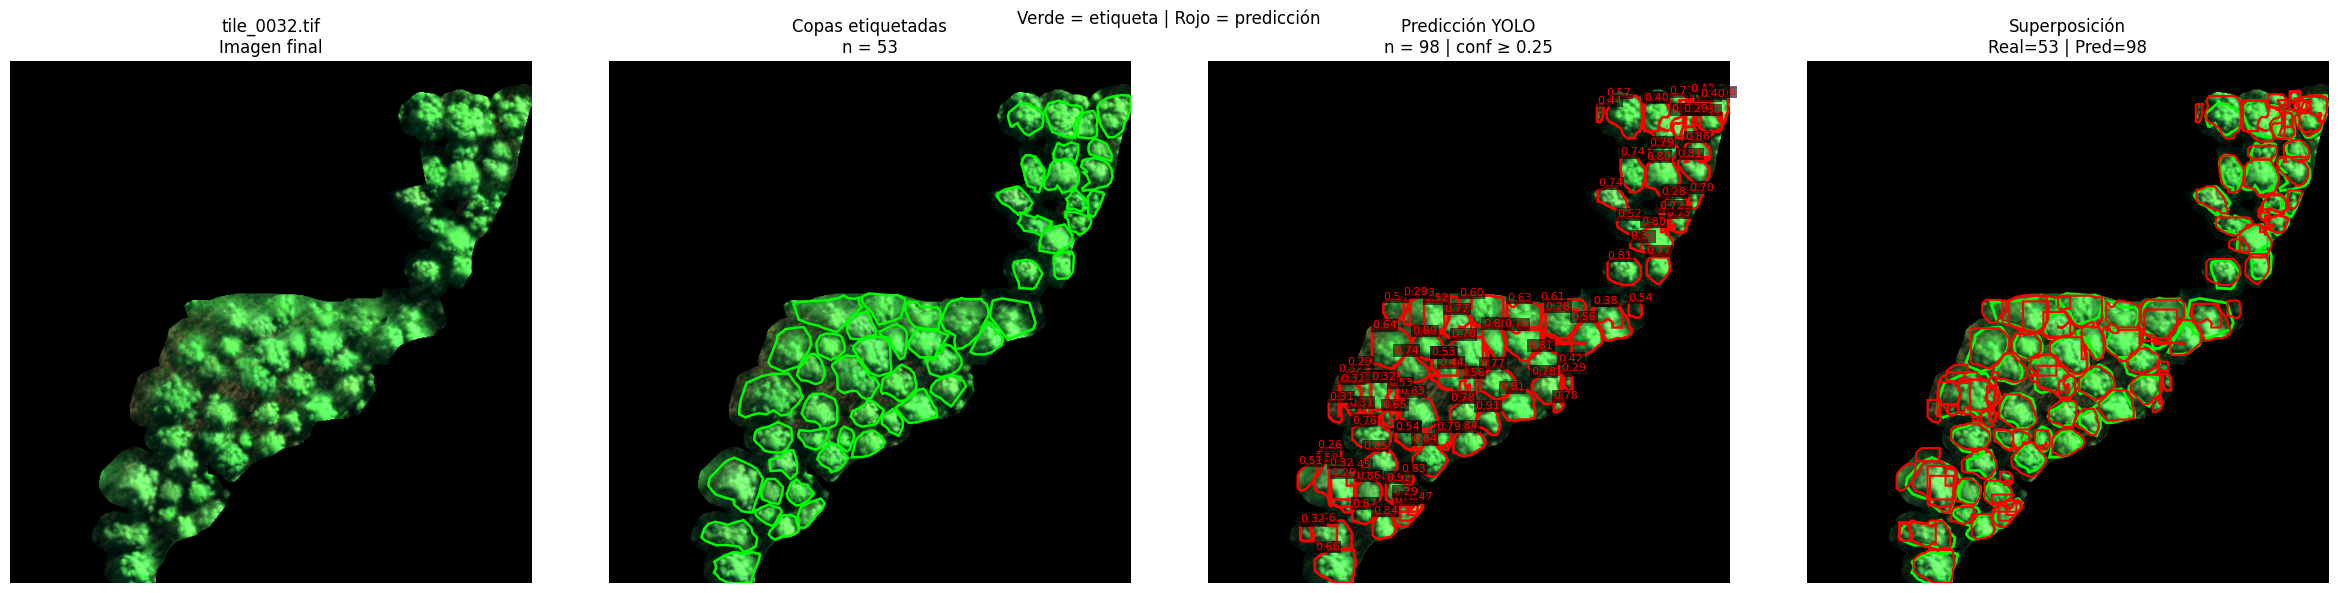

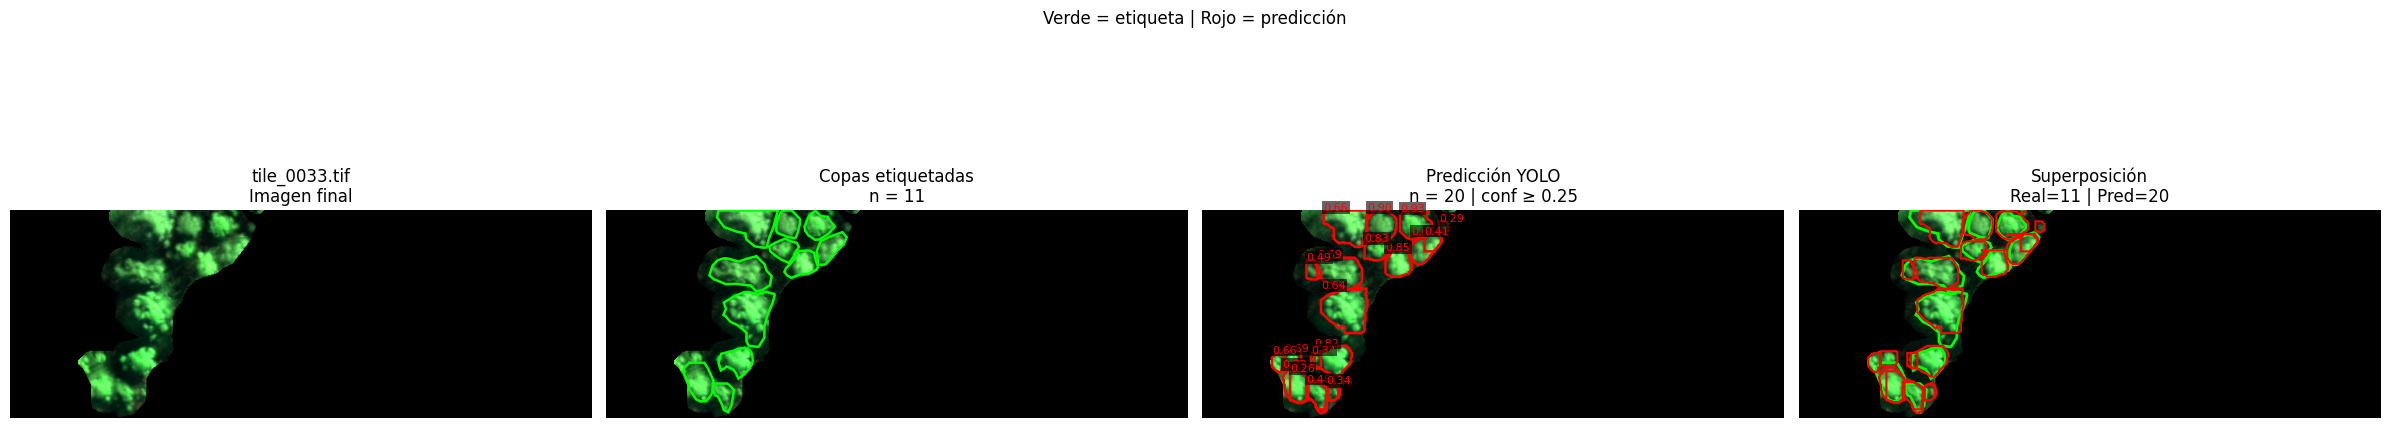

Diagnósticos guardados en: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/diagnosticos_split_bloques/teselas_real_vs_predicho


In [24]:
# Comparar visualmente máscaras reales y predichas.
from matplotlib.patches import Polygon as MplPolygon

DIAG_VIS_DIR = DIAG_DIR / 'teselas_real_vs_predicho'
DIAG_VIS_DIR.mkdir(parents=True, exist_ok=True)


def get_pred_polys(result):
    pred_polys, pred_confs = [], []
    if result.masks is None:
        return pred_polys, pred_confs

    xy_list = result.masks.xy
    confs = result.boxes.conf.cpu().numpy() if result.boxes is not None else np.repeat(np.nan, len(xy_list))

    for poly, conf in zip(xy_list, confs):
        pred_polys.append(np.asarray(poly))
        pred_confs.append(float(conf))
    return pred_polys, pred_confs


def add_polys(ax, polys, edgecolor='lime', linewidth=1.5, labels=None):
    for i, poly in enumerate(polys):
        if len(poly) < 3:
            continue
        patch = MplPolygon(poly, closed=True, fill=False, edgecolor=edgecolor, linewidth=linewidth)
        ax.add_patch(patch)
        if labels is not None and i < len(labels):
            ax.text(
                np.min(poly[:, 0]), np.min(poly[:, 1]), labels[i],
                color=edgecolor, fontsize=8,
                bbox=dict(facecolor='black', alpha=0.6, edgecolor='none', pad=1)
            )


diag_rows = []
examples_test = test_subset.head(6)

for _, r in examples_test.iterrows():
    tile_path = Path(r['image_path'])
    label_path = Path(r['label_path'])

    with rasterio.open(tile_path) as src:
        img = src.read()
        h, w = src.height, src.width

    rgb = np.moveaxis(img, 0, -1)
    if rgb.shape[-1] > 3:
        rgb = rgb[..., :3]

    gt_polys = load_yolo_polygons(label_path, w, h)

    result = best_model.predict(
        source=str(tile_path),
        imgsz=TILE_SIZE,
        conf=0.25,
        device=0,
        retina_masks=True,
        verbose=False
    )[0]

    pred_polys, pred_confs = get_pred_polys(result)

    fig, axes = plt.subplots(1, 4, figsize=(24, 6))
    for ax in axes:
        ax.imshow(rgb)
        ax.axis('off')

    axes[0].set_title(f'{tile_path.name}\nImagen final')

    add_polys(axes[1], gt_polys, 'lime', 1.8)
    axes[1].set_title(f'Copas etiquetadas\nn = {len(gt_polys)}')

    conf_labels = [f'{c:.2f}' for c in pred_confs]
    add_polys(axes[2], pred_polys, 'red', 1.8, conf_labels)
    axes[2].set_title(f'Predicción YOLO\nn = {len(pred_polys)} | conf ≥ 0.25')

    add_polys(axes[3], gt_polys, 'lime', 2.0)
    add_polys(axes[3], pred_polys, 'red', 1.5)
    axes[3].set_title(f'Superposición\nReal={len(gt_polys)} | Pred={len(pred_polys)}')

    fig.suptitle('Verde = etiqueta | Rojo = predicción')
    plt.tight_layout()

    out_path = DIAG_VIS_DIR / f'{tile_path.stem}_diagnostico.png'
    plt.savefig(out_path, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    diag_rows.append({
        'tile': tile_path.name,
        'real': len(gt_polys),
        'predicho': len(pred_polys),
        'conf_media': np.mean(pred_confs) if pred_confs else np.nan
    })

pd.DataFrame(diag_rows).to_csv(DIAG_VIS_DIR / 'resumen_diagnostico.csv', index=False)
print('Diagnósticos guardados en:', DIAG_VIS_DIR)

## 4. YOLO11n-seg
Evaluación censal completa

### 4.1 Configurar evaluación censal

In [25]:
#Reutilizar rutas comunes y cargar los pesos entrenados de YOLO11n-seg.
ROOT = BASE_DIR.parent
BASE_YOLO = BASE_DIR
DATOS_YOLO = DATA_DIR
RASTER_YOLO = RASTER_PATH
CANDIDATOS_ORIGINAL = [
    DATA_DIR / "Cerro_Alegre_Censo_Clip.tif",
    ROOT / "MASK-R-CNN" / "datos" / "Cerro_Alegre_Censo_Clip.tif",
    ROOT / "fuentes" / "Cerro_Alegre_Censo_Clip.tif"
]
TIF_ORIGINAL = next((p for p in CANDIDATOS_ORIGINAL if p.is_file()), None)
CANDIDATOS_CENSO = [
    DATA_DIR / "Censo_CerroAlegre_parcelas_12-15-16.shp",
    ROOT / "MASK-R-CNN" / "datos" / "Censo_Cerro_Alegre_parcelas_12-15-16.shp"
]
CENSO_YOLO = next((p for p in CANDIDATOS_CENSO if p.is_file()), None)
PESOS_YOLO = RUNS_DIR / "yolo11n_seg_cerro_alegre_split_bloques_100ep" / "weights" / "best.pt"
SALIDA_YOLO_CENSO = RUNS_DIR / "evaluacion_censal_definitiva_yolo11n"
SALIDA_YOLO_CENSO.mkdir(parents=True, exist_ok=True)
if TIF_ORIGINAL is None or CENSO_YOLO is None:
    raise FileNotFoundError("Falta el TIFF original o el shapefile del censo")
for ruta in (RASTER_YOLO, PESOS_YOLO):
    if not ruta.is_file(): raise FileNotFoundError(ruta)
from tqdm.auto import tqdm
from ultralytics import YOLO
import torch

# Parámetros de inferencia censal
TILE_YOLO = 640
STRIDE_YOLO = 512  # 20 % de solapamiento
CONF_YOLO = 0.25
IOU_NMS_YOLO = 0.50
MIN_AREA_PX_YOLO = 15
MIN_FRACCION_VALIDA_YOLO = 0.10

# YOLO usa GPU 0 si está disponible
import torch
DISPOSITIVO_YOLO = 0 if torch.cuda.is_available() else "cpu"

modelo_yolo_censo = YOLO(str(PESOS_YOLO))

print("YOLO11n-seg entrenado cargado")
print("Pesos:", PESOS_YOLO)
print("Raster:", RASTER_YOLO)
print("Original:", TIF_ORIGINAL)
print("Censo:", CENSO_YOLO)
print("GPU:", DISPOSITIVO_YOLO)
print("Salida:", SALIDA_YOLO_CENSO)

YOLO11n-seg entrenado cargado
Pesos: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/runs/yolo11n_seg_cerro_alegre_split_bloques_100ep/weights/best.pt
Raster: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/datos/Cerro_Alegre_Censo_Clip_uint8_global.tif
Original: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/datos/Cerro_Alegre_Censo_Clip.tif
Censo: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/datos/Censo_CerroAlegre_parcelas_12-15-16.shp
GPU: 0
Salida: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/runs/evaluacion_censal_definitiva_yolo11n


### 4.2 Máscara NoData y censo evaluable

In [26]:
#Generar máscara desde el TIFF original y filtrar el censo una única vez.
RUTA_MASCARA_YOLO = (
    SALIDA_YOLO_CENSO / "mascara_cobertura_valida.tif"
)

with rasterio.open(TIF_ORIGINAL) as src:
    nodata_original = src.nodata

    if nodata_original is None:
        raise ValueError(
            "El TIFF original no tiene NoData definido."
        )

    imagen_original = src.read([1, 2, 3])

    mascara_valida_yolo = np.all(
        ~np.isclose(imagen_original, nodata_original),
        axis=0
    )

    perfil_mascara = src.meta.copy()
    perfil_mascara.update({
        "count": 1,
        "dtype": "uint8",
        "nodata": 0
    })

with rasterio.open(RUTA_MASCARA_YOLO, "w", **perfil_mascara) as dst:
    dst.write(mascara_valida_yolo.astype(np.uint8), 1)

del imagen_original, mascara_valida_yolo

# Muestreo de puntos en una máscara, con cualquier CRS de entrada
def evaluar_puntos_mascara(geometrias, ruta_mascara):
    with rasterio.open(ruta_mascara) as msk:
        valores = []
        for geom in geometrias:
            if geom is None or geom.is_empty:
                valores.append(False)
                continue
            try:
                valor = next(msk.sample([(geom.x, geom.y)]))[0]
                valores.append(bool(valor == 1))
            except Exception:
                valores.append(False)
        return np.asarray(valores, dtype=bool)

censo_total_yolo = gpd.read_file(CENSO_YOLO)

assert censo_total_yolo.crs is not None, (
    "El censo no tiene sistema de coordenadas definido"
)

with rasterio.open(RUTA_MASCARA_YOLO) as msk:
    assert msk.crs is not None
    crs_evaluacion_yolo = msk.crs

censo_total_yolo = censo_total_yolo.to_crs(
    crs_evaluacion_yolo
)

flag_censo_yolo = evaluar_puntos_mascara(
    censo_total_yolo.geometry,
    RUTA_MASCARA_YOLO
)

censo_evaluable_yolo = (
    censo_total_yolo.loc[flag_censo_yolo]
    .copy()
    .reset_index(drop=True)
)

print("Censo total:", len(censo_total_yolo))
print("Árboles evaluables:", len(censo_evaluable_yolo))
print("Excluidos por NoData:",
      len(censo_total_yolo) - len(censo_evaluable_yolo))
print("Máscara generada:", RUTA_MASCARA_YOLO)

Censo total: 2917
Árboles evaluables: 2682
Excluidos por NoData: 235
Máscara generada: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/runs/evaluacion_censal_definitiva_yolo11n/mascara_cobertura_valida.tif


### 4.3 Inferencia en toda la ortofoto

In [28]:
# Recorrer teselas, recuperar máscaras georreferenciadas y deduplicar predicciones.
from shapely.geometry import Polygon
from rasterio.transform import xy

def inicios_yolo(total, tam, paso):
    if total <= tam:
        return [0]
    posiciones = list(range(0, total - tam + 1, paso))
    if posiciones[-1] != total - tam:
        posiciones.append(total - tam)
    return sorted(set(posiciones))

registros_yolo = []
tiles_procesados_yolo = 0
tiles_saltados_yolo = 0

with rasterio.open(RASTER_YOLO) as src:
    assert src.crs is not None
    assert src.count >= 3
    assert src.crs == crs_evaluacion_yolo, (
        "El CRS de la ortofoto preparada no coincide "
        "con el del TIFF original."
    )

    xs = inicios_yolo(src.width, TILE_YOLO, STRIDE_YOLO)
    ys = inicios_yolo(src.height, TILE_YOLO, STRIDE_YOLO)

    print("Teselas previstas:", len(xs)*len(ys))

    for y in tqdm(ys, desc="YOLO - filas"):
        for x in xs:
            w = min(TILE_YOLO, src.width-x)
            h = min(TILE_YOLO, src.height-y)
            ventana = Window(x, y, w, h)

            a = src.read(
                [1, 2, 3], window=ventana, masked=True
            )
            rgb = np.moveaxis(
                a.filled(0).astype(np.uint8), 0, -1
            )

            # La ortofoto preparada utiliza negro como NoData
            invalidos = (
                np.ma.getmaskarray(a).any(axis=0)
                | np.all(rgb == 0, axis=2)
            )

            if (~invalidos).mean() < MIN_FRACCION_VALIDA_YOLO:
                tiles_saltados_yolo += 1
                continue

            # Ultralytics interpreta los arrays numpy como BGR
            bgr = np.ascontiguousarray(rgb[:, :, ::-1])

            prediccion = modelo_yolo_censo.predict(
                source=bgr,
                imgsz=TILE_YOLO,
                conf=CONF_YOLO,
                device=DISPOSITIVO_YOLO,
                retina_masks=True,
                verbose=False
            )[0]

            tiles_procesados_yolo += 1

            if (
                prediccion.masks is None
                or prediccion.boxes is None
            ):
                continue

            tf = src.window_transform(ventana)
            scores = prediccion.boxes.conf.cpu().numpy()

            # masks.xy devuelve contornos en píxeles
            # respecto de la imagen original del tile.
            for pts, score in zip(
                prediccion.masks.xy, scores
            ):
                if len(pts) < 3:
                    continue

                # Coordenadas píxel -> coordenadas geográficas
                coords = [tf * (float(px), float(py))
                          for px, py in pts]

                poligono = Polygon(coords)

                if not poligono.is_valid:
                    poligono = poligono.buffer(0)

                if poligono.is_empty:
                    continue

                # Área mínima equivalente en píxeles
                area_pixel = abs(tf.a * tf.e - tf.b * tf.d)
                if poligono.area / area_pixel < MIN_AREA_PX_YOLO:
                    continue

                registros_yolo.append({
                    "score": float(score),
                    "geometry": poligono
                })

print("\nTiles procesados:", tiles_procesados_yolo)
print("Tiles saltados:", tiles_saltados_yolo)
print("Propuestas crudas:", len(registros_yolo))

# Deduplicación por IoU --------

propuestas_yolo = gpd.GeoDataFrame(
    registros_yolo,
    columns=["score", "geometry"],
    geometry="geometry",
    crs=crs_evaluacion_yolo
)

propuestas_yolo = propuestas_yolo.sort_values(
    "score", ascending=False
).reset_index(drop=True)

indices_conservados = []
indices_conservados_set = set()

if len(propuestas_yolo):
    indice_espacial = propuestas_yolo.sindex

    for i in tqdm(
        range(len(propuestas_yolo)),
        desc="Eliminando duplicados"
    ):
        geom = propuestas_yolo.geometry.iloc[i]
        es_duplicado = False

        vecinos = indice_espacial.query(
            geom, predicate="intersects"
        )

        for j in vecinos:
            j = int(j)

            # Comparar SOLO con detecciones conservadas
            if j not in indices_conservados_set:
                continue

            otra = propuestas_yolo.geometry.iloc[j]
            union = geom.union(otra).area

            if union <= 0:
                continue

            iou = geom.intersection(otra).area / union

            if iou >= IOU_NMS_YOLO:
                es_duplicado = True
                break

        if not es_duplicado:
            indices_conservados.append(i)
            indices_conservados_set.add(i)

predicciones_unicas_yolo = (
    propuestas_yolo.iloc[indices_conservados]
    .copy()
    .reset_index(drop=True)
)

print("Propuestas originales:", len(propuestas_yolo))
print("Detecciones únicas:", len(predicciones_unicas_yolo))
print("Duplicados eliminados:",
      len(propuestas_yolo)-len(predicciones_unicas_yolo))

print("Inferencia y deduplicación completadas")

Teselas previstas: 52


YOLO - filas:   0%|          | 0/13 [00:00<?, ?it/s]


Tiles procesados: 34
Tiles saltados: 18
Propuestas crudas: 6153


Eliminando duplicados:   0%|          | 0/6153 [00:00<?, ?it/s]

Propuestas originales: 6153
Detecciones únicas: 3979
Duplicados eliminados: 2174
Inferencia y deduplicación completadas


### 4.4 Correspondencia espacial y métricas

In [29]:
#Calcular TP, FP, FN y error de conteo con el censo evaluable.
# Filtrar detecciones por la máscara regenerada
flag_pred_yolo = evaluar_puntos_mascara(
    predicciones_unicas_yolo.geometry.centroid,
    RUTA_MASCARA_YOLO
)

pred_eval_yolo = (
    predicciones_unicas_yolo.loc[flag_pred_yolo]
    .copy()
    .reset_index(drop=True)
)

ref_yolo = censo_evaluable_yolo.copy().reset_index(drop=True)

ref_yolo["id_punto"] = np.arange(len(ref_yolo))
pred_eval_yolo["id_pred"] = np.arange(len(pred_eval_yolo))

# Asociación espacial: punto dentro de copa
if len(pred_eval_yolo):
    relaciones_yolo = gpd.sjoin(
        ref_yolo[["id_punto", "geometry"]],
        pred_eval_yolo[["id_pred", "geometry"]],
        how="inner",
        predicate="within"
    )
else:
    relaciones_yolo = pd.DataFrame(
        columns=["id_punto", "id_pred", "distancia"]
    )

matches_yolo = []
usados_ref_yolo = set()
usados_pred_yolo = set()

if len(relaciones_yolo):
    puntos_yolo = (
        ref_yolo.set_index("id_punto").geometry
    )
    centros_yolo = (
        pred_eval_yolo.set_index("id_pred").geometry.centroid
    )

    relaciones_yolo["distancia"] = relaciones_yolo.apply(
        lambda r: puntos_yolo.loc[r["id_punto"]].distance(
            centros_yolo.loc[r["id_pred"]]
        ),
        axis=1
    )

    relaciones_yolo = relaciones_yolo.sort_values("distancia")

    for _, r in relaciones_yolo.iterrows():
        i = int(r["id_punto"])
        j = int(r["id_pred"])

        if i not in usados_ref_yolo and j not in usados_pred_yolo:
            usados_ref_yolo.add(i)
            usados_pred_yolo.add(j)

            matches_yolo.append({
                "id_punto": i,
                "id_pred": j,
                "distancia_m": float(r["distancia"])
            })

# Métricas
N_REAL_YOLO = len(ref_yolo)
N_PRED_YOLO = len(pred_eval_yolo)

TP_YOLO = len(matches_yolo)
FP_YOLO = N_PRED_YOLO - TP_YOLO
FN_YOLO = N_REAL_YOLO - TP_YOLO

PRECISION_YOLO = (
    TP_YOLO / N_PRED_YOLO if N_PRED_YOLO else 0
)

RECALL_YOLO = TP_YOLO / N_REAL_YOLO

F1_YOLO = (
    2 * PRECISION_YOLO * RECALL_YOLO
    / (PRECISION_YOLO + RECALL_YOLO)
    if PRECISION_YOLO + RECALL_YOLO else 0
)

ERROR_YOLO = (
    100 * (N_PRED_YOLO - N_REAL_YOLO) / N_REAL_YOLO
)

resultado_final_yolo = pd.DataFrame([{
    "modelo": "YOLO11n-seg",
    "censo_evaluable": N_REAL_YOLO,
    "detecciones": N_PRED_YOLO,
    "TP": TP_YOLO,
    "FP": FP_YOLO,
    "FN": FN_YOLO,
    "precision": PRECISION_YOLO,
    "recall": RECALL_YOLO,
    "F1": F1_YOLO,
    "error_conteo_pct": ERROR_YOLO,
    "error_absoluto_pct": abs(ERROR_YOLO)
}])

assert TP_YOLO + FP_YOLO == N_PRED_YOLO
assert TP_YOLO + FN_YOLO == N_REAL_YOLO

print("YOLO11n-seg — RESULTADO CENSAL DEFINITIVO")
display(resultado_final_yolo.round(4))

print("\nCONTROL DEL PROCESAMIENTO")
print("Propuestas crudas:", len(propuestas_yolo))
print("Después de deduplicar:", len(predicciones_unicas_yolo))
print("Después de NoData:", N_PRED_YOLO)
print("Árboles evaluables:", N_REAL_YOLO)

# Exportar archivos finales
resultado_final_yolo.to_csv(
    SALIDA_YOLO_CENSO / "YOLO11n_METRICAS_CENSO.csv",
    index=False
)

pd.DataFrame(
    matches_yolo,
    columns=["id_punto", "id_pred", "distancia_m"]
).to_csv(
    SALIDA_YOLO_CENSO / "YOLO11n_MATCHES_CENSO.csv",
    index=False
)

ref_yolo.to_file(
    SALIDA_YOLO_CENSO / "censo_evaluable.gpkg",
    driver="GPKG"
)

if len(pred_eval_yolo):
    pred_eval_yolo.to_file(
        SALIDA_YOLO_CENSO / "detecciones_yolo11n.gpkg",
        driver="GPKG"
    )

print("\nResultados guardados en:", SALIDA_YOLO_CENSO)

YOLO11n-seg — RESULTADO CENSAL DEFINITIVO


,modelo,censo_evaluable,detecciones,TP,FP,FN,precision,recall,F1,error_conteo_pct,error_absoluto_pct
0,YOLO11n-seg,2682,3979,2614,1365,68,0.6569,0.9746,0.7849,48.3594,48.3594



CONTROL DEL PROCESAMIENTO
Propuestas crudas: 6153
Después de deduplicar: 3979
Después de NoData: 3979
Árboles evaluables: 2682

Resultados guardados en: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/runs/evaluacion_censal_definitiva_yolo11n


### 4.5 Mapa final

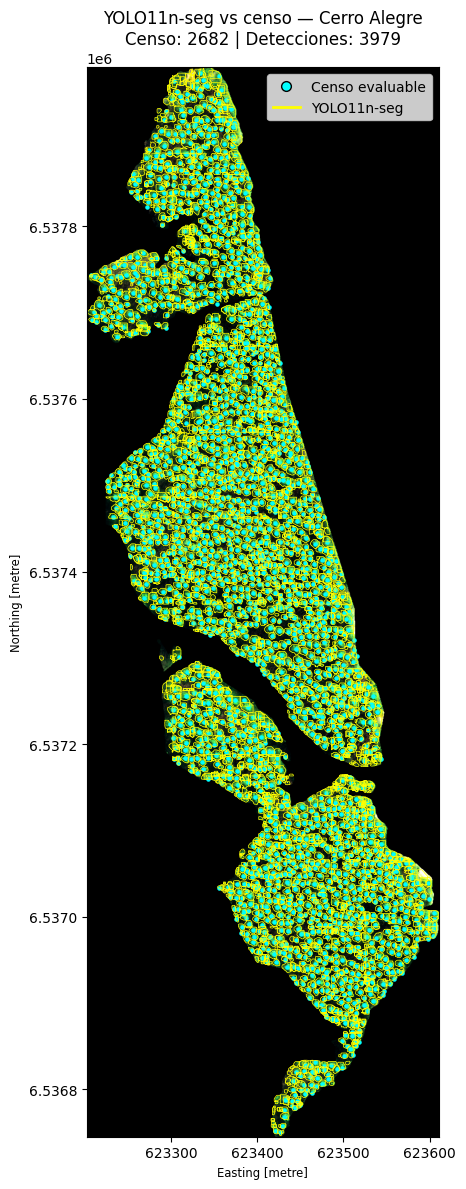

Mapa guardado: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/runs/evaluacion_censal_definitiva_yolo11n/YOLO11n_MAPA_CENSO.png


In [31]:
#Visualizar resultados y errores sobre la ortofoto.
from matplotlib.lines import Line2D

with rasterio.open(RASTER_YOLO) as src:
    # Vista reducida para no cargar el raster completo
    escala = max(1, int(max(src.width, src.height) / 1800))
    rgb_mapa = src.read(
        [1, 2, 3],
        out_shape=(
            3,
            max(1, src.height // escala),
            max(1, src.width // escala)
        )
    )
    rgb_mapa = np.moveaxis(rgb_mapa, 0, -1)
    bounds = src.bounds

fig, ax = plt.subplots(figsize=(12, 12))

ax.imshow(
    rgb_mapa,
    extent=(
        bounds.left, bounds.right,
        bounds.bottom, bounds.top
    ),
    origin="upper"
)

if len(pred_eval_yolo):
    pred_eval_yolo.boundary.plot(
        ax=ax, color="yellow", linewidth=0.5
    )

ref_yolo.plot(
    ax=ax, color="cyan", markersize=5
)

leyenda = [
    Line2D([0], [0], marker="o", color="none",
           markerfacecolor="cyan", markersize=7,
           label="Censo evaluable"),
    Line2D([0], [0], color="yellow",
           linewidth=2, label="YOLO11n-seg")
]

ax.legend(handles=leyenda, loc="upper right")
ax.set_title(
    f"YOLO11n-seg vs censo — Cerro Alegre\n"
    f"Censo: {N_REAL_YOLO} | Detecciones: {N_PRED_YOLO}"
)

plt.tight_layout()

ruta_png = (
    SALIDA_YOLO_CENSO / "YOLO11n_MAPA_CENSO.png"
)
fig.savefig(ruta_png, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Mapa guardado:", ruta_png)

## 5. YOLO11s-seg
Entrenamiento y test

### 5.1 Configuración YOLO11s-seg

In [32]:
from pathlib import Path
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

BASE_DIR = BASE_DIR
DATASET_DIR = DATASET_DIR
RUNS_DIR = RUNS_DIR
YAML_PATH = DATASET_DIR / "data.yaml"

TILE_SIZE = 640
BATCH = 8
EPOCHS = 100
SEED = 42
WORKERS = 2
PATIENCE = 25

RUN_NAME = "yolo11s_seg_cerro_alegre_split_bloques_100ep"
RUN_DIR = RUNS_DIR / RUN_NAME

print("DATASET_DIR:", DATASET_DIR)
print("YAML_PATH:", YAML_PATH)
print("RUN_DIR:", RUN_DIR)


DATASET_DIR: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/dataset_yolo_split_bloques
YAML_PATH: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/dataset_yolo_split_bloques/data.yaml
RUN_DIR: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/runs/yolo11s_seg_cerro_alegre_split_bloques_100ep


### 5.2 Comprobar dataset

In [33]:
assert DATASET_DIR.exists(), f"No existe: {DATASET_DIR}"
assert YAML_PATH.exists(), f"No existe: {YAML_PATH}"

with open(YAML_PATH, "r") as f:
    data_cfg = yaml.safe_load(f)

print("data.yaml:")
print(data_cfg)

for split in ["train", "val", "test"]:
    img_dir = DATASET_DIR / "images" / split
    lbl_dir = DATASET_DIR / "labels" / split
    imgs = sorted(img_dir.glob("*.tif"))
    labels = sorted(lbl_dir.glob("*.txt"))
    print(f"{split:5s} | imágenes: {len(imgs):2d} | labels: {len(labels):2d}")

print("\nEsperado:")
print("train = 10 tiles")
print("val   = 4 tiles")
print("test  = 2 tiles")


data.yaml:
{'path': '/content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/dataset_yolo_split_bloques', 'train': 'images/train', 'val': 'images/val', 'test': 'images/test', 'names': {0: 'tree'}}
train | imágenes: 10 | labels: 10
val   | imágenes:  4 | labels:  4
test  | imágenes:  2 | labels:  2

Esperado:
train = 10 tiles
val   = 4 tiles
test  = 2 tiles


### 5.3 Cargar pesos iniciales

In [35]:
model_s = YOLO("yolo11s-seg.pt")


### 5.4 Entrenar YOLO11s-seg

In [36]:
# Entrenamiento formal con sus propios hiperparámetros.
train_results_s = model_s.train(
    data=str(YAML_PATH),
    epochs=EPOCHS,
    imgsz=TILE_SIZE,
    batch=BATCH,
    device=0,
    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=False,
    seed=SEED,
    workers=WORKERS,
    plots=True,
    patience=PATIENCE
)


Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/dataset_yolo_split_bloques/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s-seg.pt, momentum=0.937, mosaic=1.

### 5.5 Cargar mejores pesos

In [38]:
BEST_MODEL = RUN_DIR / "weights" / "best.pt"
best_s = YOLO(str(BEST_MODEL))
print(BEST_MODEL)


/content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/runs/yolo11s_seg_cerro_alegre_split_bloques_100ep/weights/best.pt


### 5.6 Validación

In [42]:
#Calcular métricas
val_metrics_s = best_s.val(
    data=str(YAML_PATH),
    split="val",
    imgsz=TILE_SIZE,
    batch=BATCH,
    device=0,
    project=str(RUNS_DIR),
    name="evaluacion_val_yolo11s_split_bloques",
    exist_ok=True,
    plots=True
)


Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 1.2±1.1 ms, read: 198.0±49.7 MB/s, size: 548.0 KB)
val: Scanning /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/dataset_yolo_split_bloques/labels/val.cache... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4 762.6Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.4it/s 0.7s
                   all          4        340      0.223      0.535      0.322     0.0737     0.0417        0.1     0.0188    0.00281
Speed: 1.8ms preprocess, 20.6ms inference, 0.0ms loss, 9.1ms postprocess per image
Results saved to /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/runs/evaluacion_val_yolo11s_split_bloques


### 5.7 Evaluación en test

In [43]:
#Calcular métricas en test.
test_metrics_s = best_s.val(
    data=str(YAML_PATH),
    split="test",
    imgsz=TILE_SIZE,
    batch=BATCH,
    device=0,
    project=str(RUNS_DIR),
    name="evaluacion_test_yolo11s_split_bloques",
    exist_ok=True,
    plots=True
)


Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.2 ms, read: 165.1±115.5 MB/s, size: 218.9 KB)
val: Scanning /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/dataset_yolo_split_bloques/labels/test.cache... 2 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2/2 441.5Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 3.9it/s 0.3s
                   all          2         64      0.254      0.766      0.607      0.174     0.0675      0.203      0.114      0.026
Speed: 0.7ms preprocess, 25.0ms inference, 0.0ms loss, 8.2ms postprocess per image
Results saved to /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/runs/evaluacion_test_yolo11s_split_bloques


### 5.8 Resumen de métricas

In [44]:
metrics = test_metrics_s.results_dict

metrics_table = pd.DataFrame({
    "métrica": [
        "Precision Box",
        "Recall Box",
        "mAP50 Box",
        "mAP50-95 Box",
        "Precision Mask",
        "Recall Mask",
        "mAP50 Mask",
        "mAP50-95 Mask",
    ],
    "YOLO11s-Seg": [
        metrics.get("metrics/precision(B)", np.nan),
        metrics.get("metrics/recall(B)", np.nan),
        metrics.get("metrics/mAP50(B)", np.nan),
        metrics.get("metrics/mAP50-95(B)", np.nan),
        metrics.get("metrics/precision(M)", np.nan),
        metrics.get("metrics/recall(M)", np.nan),
        metrics.get("metrics/mAP50(M)", np.nan),
        metrics.get("metrics/mAP50-95(M)", np.nan),
    ]
})

display(metrics_table)


,métrica,YOLO11s-Seg
0,Precision Box,0.254426
1,Recall Box,0.765625
2,mAP50 Box,0.606621
3,mAP50-95 Box,0.173541
4,Precision Mask,0.067501
5,Recall Mask,0.203125
6,mAP50 Mask,0.113592
7,mAP50-95 Mask,0.025977


### 5.9 Conteo en test

In [45]:
#Evaluar conteos por tesela en el conjunto de prueba.
TEST_IMG_DIR = DATASET_DIR / "images" / "test"
TEST_LBL_DIR = DATASET_DIR / "labels" / "test"

test_images = sorted(TEST_IMG_DIR.glob("*.tif"))
rows = []

for image_path in test_images:
    label_path = TEST_LBL_DIR / f"{image_path.stem}.txt"

    if label_path.exists():
        with open(label_path, "r") as f:
            n_real = sum(1 for line in f if line.strip())
    else:
        n_real = 0

    pred = best_s.predict(
        source=str(image_path),
        imgsz=TILE_SIZE,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    n_pred = 0 if pred.boxes is None else len(pred.boxes)

    rows.append({
        "tile": image_path.name,
        "real": n_real,
        "predicho": n_pred,
        "error": n_pred - n_real,
        "error_abs": abs(n_pred - n_real),
        "error_pct": np.nan if n_real == 0 else abs(n_pred - n_real) / n_real * 100
    })

count_df = pd.DataFrame(rows)
display(count_df)

print("\nTotal real (apariciones en tiles):", count_df["real"].sum())
print("Total predicho:", count_df["predicho"].sum())
print("Sesgo total:", count_df["predicho"].sum() - count_df["real"].sum())
print("MAE por tile:", count_df["error_abs"].mean())
print("MAPE (%):", count_df["error_pct"].mean())


,tile,real,predicho,error,error_abs,error_pct
0,tile_0032.tif,53,227,174,174,328.301887
1,tile_0033.tif,11,109,98,98,890.909091



Total real (apariciones en tiles): 64
Total predicho: 336
Sesgo total: 272
MAE por tile: 136.0
MAPE (%): 609.6054888507718


## 6. Comparación de variantes YOLO

### 6.1 Comparar métricas de test

In [46]:
# Métricas del test de YOLO11n-seg obtenidas.
claves = {
    "Precision Box": "metrics/precision(B)", "Recall Box": "metrics/recall(B)",
    "mAP50 Box": "metrics/mAP50(B)", "mAP50-95 Box": "metrics/mAP50-95(B)",
    "Precision Mask": "metrics/precision(M)", "Recall Mask": "metrics/recall(M)",
    "mAP50 Mask": "metrics/mAP50(M)", "mAP50-95 Mask": "metrics/mAP50-95(M)"
}
n_results = {nombre: test_metrics.results_dict.get(clave, np.nan) for nombre, clave in claves.items()}
s_results = {nombre: test_metrics_s.results_dict.get(clave, np.nan) for nombre, clave in claves.items()}
comparison = pd.DataFrame({
    "métrica": list(claves),
    "YOLO11n-Seg": [n_results[k] for k in claves],
    "YOLO11s-Seg": [s_results[k] for k in claves]
})
comparison["diferencia_s_menos_n"] = comparison["YOLO11s-Seg"] - comparison["YOLO11n-Seg"]
display(comparison)


,métrica,YOLO11n-Seg,YOLO11s-Seg,diferencia_s_menos_n
0,Precision Box,0.789493,0.254426,-0.535066
1,Recall Box,0.820465,0.765625,-0.054840
2,mAP50 Box,0.880015,0.606621,-0.273394
3,mAP50-95 Box,0.490792,0.173541,-0.317251
4,Precision Mask,0.804529,0.067501,-0.737028
5,Recall Mask,0.836090,0.203125,-0.632965
6,mAP50 Mask,0.897242,0.113592,-0.783650
7,mAP50-95 Mask,0.452208,0.025977,-0.426231


### 6.2 Exportar comparación

In [47]:
# Guardar las tablas de comparación y conteo.
OUT_CSV = RUN_DIR / "comparacion_yolo11n_vs_yolo11s.csv"
COUNT_CSV = RUN_DIR / "conteo_test_conf025.csv"

comparison.to_csv(OUT_CSV, index=False)
count_df.to_csv(COUNT_CSV, index=False)

print("Comparación:", OUT_CSV)
print("Conteo:", COUNT_CSV)


Comparación: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/runs/yolo11s_seg_cerro_alegre_split_bloques_100ep/comparacion_yolo11n_vs_yolo11s.csv
Conteo: /content/drive/MyDrive/Maestría Ciencia de Datos/Tesis/proyecto/Entrega/runs/yolo11s_seg_cerro_alegre_split_bloques_100ep/conteo_test_conf025.csv
